## 1. Импорт библиотек и настройка окружения

Подключаем все необходимые библиотеки:
- `pandas`, `numpy` — работа с данными;
- `matplotlib`, `seaborn` — визуализация;
- `sklearn` — модели, метрики, предобработка, `GridSearchCV`.

Фиксируем `random_state = 42` для воспроизводимости результатов.

**Вариант:** чётный → **Random Forest** (задача регрессии: предсказываем `Exam_Score`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Метрики регрессии
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Модель
from sklearn.ensemble import RandomForestRegressor

# Настройки отображения
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Библиотеки успешно импортированы.")
print(f"pandas: {pd.__version__}, numpy: {np.__version__}")

Библиотеки успешно импортированы.
pandas: 2.2.3, numpy: 2.4.6


## 2. Подключение Google Drive и загрузка датасета

Подключаем Google Drive (для Colab), проверяем наличие файла по пути `DATA_PATH` и загружаем CSV в `DataFrame`. Печатаем размер таблицы и первые строки для контроля.

In [2]:

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print("Не Colab или Drive уже подключён:", e)

DATA_PATH = Path(
    "/content/drive/MyDrive/colab_data/StudentPerformanceFactors.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Файл не найден: {DATA_PATH}\n"
        "Проверьте, что StudentPerformanceFactors.csv "
        "находится в папке MyDrive/colab_data/"
    )

df = pd.read_csv(DATA_PATH)
print("Размер датасета:", df.shape)
df.head()

Mounted at /content/drive
Размер датасета: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## 3. Первичный обзор данных

Смотрим:
- типы признаков (`dtypes`);
- пропуски по столбцам;
- описательные статистики числовых признаков (`describe`);
- уникальные значения категориальных столбцов.

Целевая переменная — `Exam_Score` (числовая, регрессия).

In [3]:

print("=== Типы признаков ===")
print(df.dtypes)

print("\n=== Пропуски по столбцам ===")
print(df.isna().sum()[df.isna().sum() > 0])

print("\n=== Описательные статистики числовых признаков ===")
display(df.describe().T)

print("\n=== Уникальные категориальные значения ===")
cat_cols_preview = df.select_dtypes(include="object").columns
for col in cat_cols_preview:
    print(f"{col}: {df[col].unique()}")

=== Типы признаков ===
Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer_Influence                object
Physical_Activity              int64
Learning_Disabilities         object
Parental_Education_Level      object
Distance_from_Home            object
Gender                        object
Exam_Score                     int64
dtype: object

=== Пропуски по столбцам ===
Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64

=== Описательные статистики числовых признаков ===


,count,mean,std,min,25%,50%,75%,max
Hours_Studied,6607.0,19.975329,5.990594,1.0,16.0,20.0,24.0,44.0
Attendance,6607.0,79.977448,11.547475,60.0,70.0,80.0,90.0,100.0
Sleep_Hours,6607.0,7.029060,1.468120,4.0,6.0,7.0,8.0,10.0
Previous_Scores,6607.0,75.070531,14.399784,50.0,63.0,75.0,88.0,100.0
Tutoring_Sessions,6607.0,1.493719,1.230570,0.0,1.0,1.0,2.0,8.0
Physical_Activity,6607.0,2.967610,1.031231,0.0,2.0,3.0,4.0,6.0
Exam_Score,6607.0,67.235659,3.890456,55.0,65.0,67.0,69.0,101.0



=== Уникальные категориальные значения ===
Parental_Involvement: ['Low' 'Medium' 'High']
Access_to_Resources: ['High' 'Medium' 'Low']
Extracurricular_Activities: ['No' 'Yes']
Motivation_Level: ['Low' 'Medium' 'High']
Internet_Access: ['Yes' 'No']
Family_Income: ['Low' 'Medium' 'High']
Teacher_Quality: ['Medium' 'High' 'Low' nan]
School_Type: ['Public' 'Private']
Peer_Influence: ['Positive' 'Negative' 'Neutral']
Learning_Disabilities: ['No' 'Yes']
Parental_Education_Level: ['High School' 'College' 'Postgraduate' nan]
Distance_from_Home: ['Near' 'Moderate' 'Far' nan]
Gender: ['Male' 'Female']


## 4. Разведочный анализ: распределение цели и корреляции

Строим распределение целевой переменной `Exam_Score` и корреляционную матрицу для числовых признаков. Определяем, какие числовые признаки сильнее всего связаны с целевой переменной.

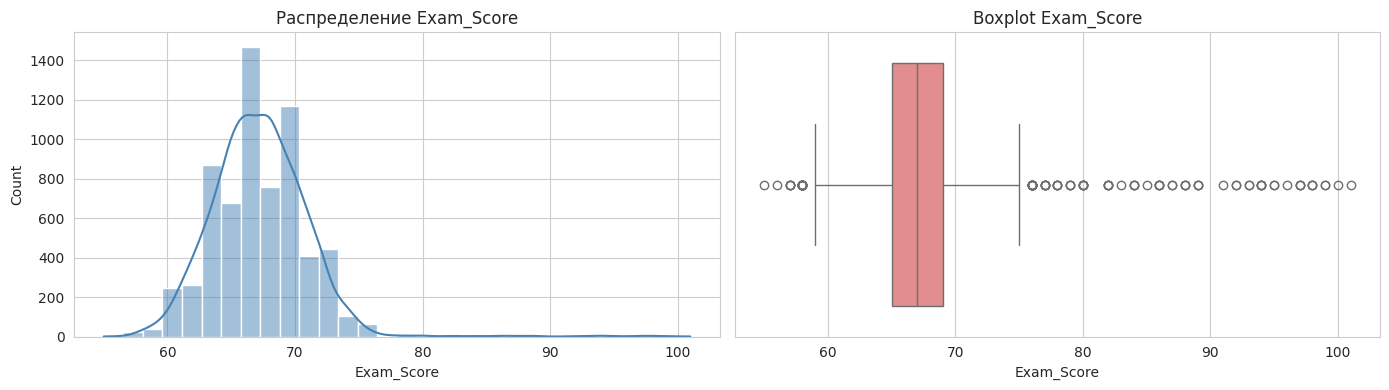

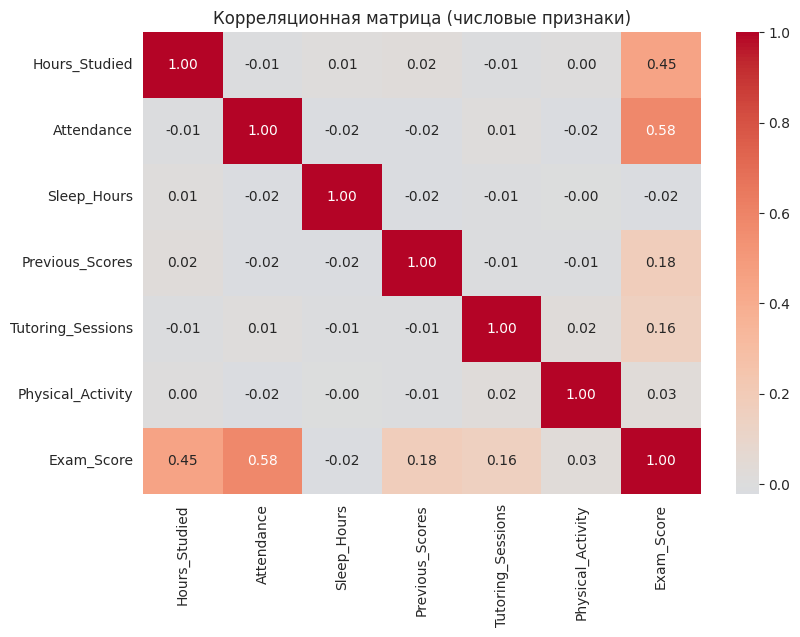

Корреляция признаков с Exam_Score:
 Attendance           0.581072
Hours_Studied        0.445455
Previous_Scores      0.175079
Tutoring_Sessions    0.156525
Physical_Activity    0.027824
Sleep_Hours         -0.017022
Name: Exam_Score, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(df["Exam_Score"], kde=True, bins=30, ax=axes[0], color="steelblue")
axes[0].set_title("Распределение Exam_Score")
axes[0].set_xlabel("Exam_Score")

sns.boxplot(x=df["Exam_Score"], ax=axes[1], color="lightcoral")
axes[1].set_title("Boxplot Exam_Score")

plt.tight_layout()
plt.show()

# Корреляционная матрица только для числовых признаков
num_df = df.select_dtypes(include=["int64", "float64"])
plt.figure(figsize=(9, 6))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляционная матрица (числовые признаки)")
plt.show()

corr_target = (
    num_df.corr()["Exam_Score"]
    .drop("Exam_Score")
    .sort_values(key=abs, ascending=False)
)
print("Корреляция признаков с Exam_Score:\n", corr_target)

## 5. Предобработка: разделение X / y и типы столбцов

1. Отделяем целевую переменную `Exam_Score` от матрицы признаков `X`.
2. Делим признаки на **числовые** и **категориальные**.
3. Формируем `ColumnTransformer`:
   - числовые — импутация медианой (масштабирование **не требуется** для Random Forest);
   - категориальные — импутация модой + One-Hot Encoding.

In [5]:

TARGET = "Exam_Score"

X = df.drop(columns=[TARGET])
y = df[TARGET]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)
print("\nПропуски в категориальных:", X[categorical_features].isna().sum().sum())
print("Пропуски в числовых:", X[numeric_features].isna().sum().sum())

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

Числовые признаки: ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
Категориальные признаки: ['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Пропуски в категориальных: 235
Пропуски в числовых: 0


## 6. Train/Test split и обучение базовой модели

Делим данные на train/test в пропорции 80/20. Собираем `Pipeline` из `ColumnTransformer` и `RandomForestRegressor` **с параметрами по умолчанию**. Обучаем на тренировочной части и получаем прогнозы на тестовой.

In [6]:

import time

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

rf_baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

t0 = time.time()
rf_baseline.fit(X_train, y_train)
train_time_baseline = time.time() - t0
print(f"Обучение базовой модели: {train_time_baseline:.2f} сек.")

y_pred_baseline = rf_baseline.predict(X_test)
print("Прогнозы на тесте получены.")

Train: (5285, 19), Test: (1322, 19)
Обучение базовой модели: 4.81 сек.
Прогнозы на тесте получены.


## 7. Метрики качества базовой модели

Считаем метрики для регрессии согласно ТЗ:
- **MSE** — mean squared error;
- **RMSE** — корень из MSE (в баллах);
- **MAE** — mean absolute error;
- **R²** — коэффициент детерминации.

Метрики считаем на train и test — чтобы увидеть переобучение.

In [7]:

def regression_metrics(y_true, y_pred, name=""):
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    if name:
        print(f"--- {name} ---")
    print(f"MSE  : {mse:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"MAE  : {mae:.4f}")
    print(f"R²   : {r2:.4f}")
    return {"MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

metrics_baseline_train = regression_metrics(
    y_train, rf_baseline.predict(X_train), "Baseline (train)"
)
print()
metrics_baseline_test = regression_metrics(
    y_test, y_pred_baseline, "Baseline (test)"
)

--- Baseline (train) ---
MSE  : 0.7963
RMSE : 0.8923
MAE  : 0.4373
R²   : 0.9482

--- Baseline (test) ---
MSE  : 4.6904
RMSE : 2.1657
MAE  : 1.0841
R²   : 0.6682


## 8. Визуализация результатов базовой модели

Для задачи регрессии вместо матрицы ошибок строим:
- **Actual vs Predicted** — точки должны группироваться вдоль диагонали `y = x`;
- **Residuals plot** — остатки `y − ŷ` должны быть симметричны относительно нуля.

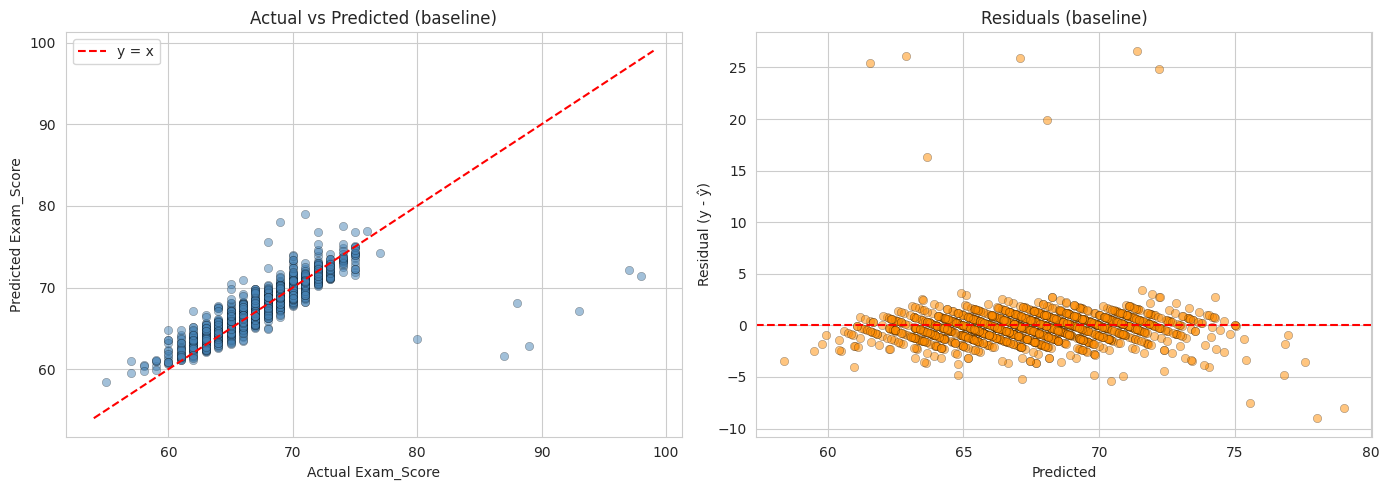

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_baseline, alpha=0.5,
                color="steelblue", edgecolor="k", linewidth=0.3)
lims = [min(y_test.min(), y_pred_baseline.min()) - 1,
        max(y_test.max(), y_pred_baseline.max()) + 1]
axes[0].plot(lims, lims, "r--", label="y = x")
axes[0].set_xlabel("Actual Exam_Score")
axes[0].set_ylabel("Predicted Exam_Score")
axes[0].set_title("Actual vs Predicted (baseline)")
axes[0].legend()

residuals = y_test - y_pred_baseline
axes[1].scatter(y_pred_baseline, residuals, alpha=0.5,
                color="darkorange", edgecolor="k", linewidth=0.3)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residual (y - ŷ)")
axes[1].set_title("Residuals (baseline)")

plt.tight_layout()
plt.show()

## 9. Подбор гиперпараметров через GridSearchCV

Согласно п.5–6 задания настраиваем:
- `n_estimators` — число деревьев;
- `max_depth` — максимальная глубина;
- `min_samples_split` — минимум объектов для разбиения;
- `min_samples_leaf` — минимум объектов в листе;
- `max_features` — число признаков на разбиение.

Стратегия кросс-валидации: `cv=3`, метрика `neg_root_mean_squared_error`.

In [9]:

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", 0.5],
}

rf_pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

grid_search = GridSearchCV(
    estimator=rf_pipe,
    param_grid=param_grid,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

t0 = time.time()
grid_search.fit(X_train, y_train)
grid_time = time.time() - t0
print(f"\nGridSearch завершён за {grid_time:.1f} сек.")
print("Лучшие параметры:", grid_search.best_params_)
print(f"Лучший CV RMSE: {-grid_search.best_score_:.4f}")

Fitting 3 folds for each of 48 candidates, totalling 144 fits

GridSearch завершён за 215.9 сек.
Лучшие параметры: {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Лучший CV RMSE: 2.3354


## 10. Оценка лучшей модели и сравнение с baseline

Берём `best_estimator_` из GridSearchCV, считаем метрики на train/test и строим сводную таблицу для сравнения с базовой моделью. Дополнительно визуализируем прогнозы и остатки лучшей модели.

--- Tuned (train) ---
MSE  : 2.1263
RMSE : 1.4582
MAE  : 0.5645
R²   : 0.8618

--- Tuned (test) ---
MSE  : 4.2382
RMSE : 2.0587
MAE  : 0.9939
R²   : 0.7002

=== Сравнение моделей (test) ===


,Baseline (test),Tuned (test)
MSE,4.6904,4.2382
RMSE,2.1657,2.0587
MAE,1.0841,0.9939
R2,0.6682,0.7002


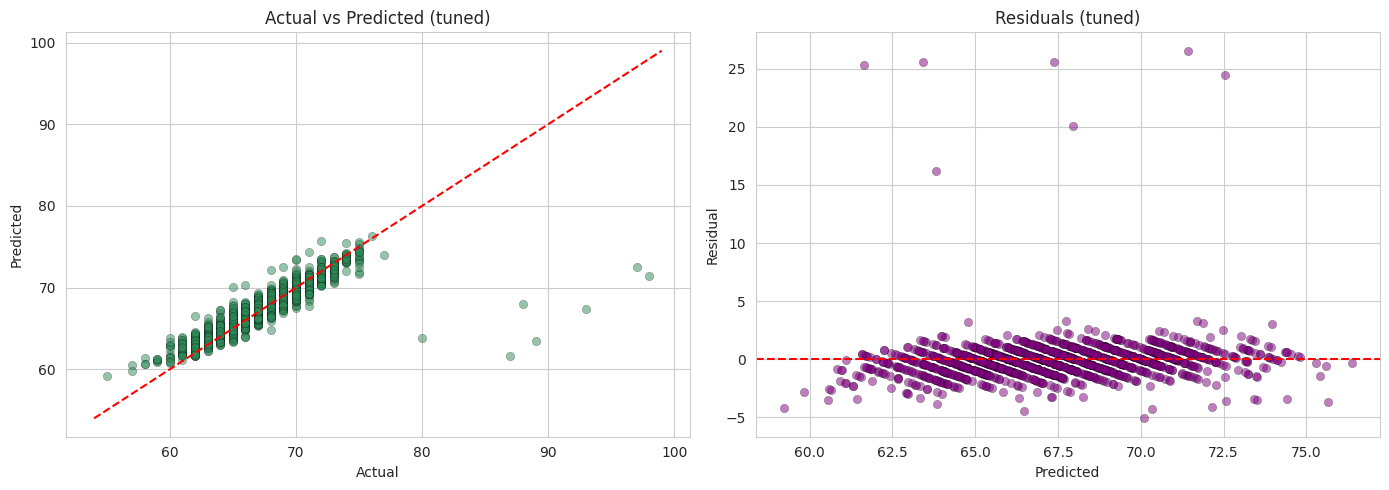

In [10]:

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)

metrics_best_train = regression_metrics(
    y_train, best_model.predict(X_train), "Tuned (train)"
)
print()
metrics_best_test = regression_metrics(
    y_test, y_pred_best, "Tuned (test)"
)

comparison = pd.DataFrame({
    "Baseline (test)": metrics_baseline_test,
    "Tuned (test)":    metrics_best_test
}).round(4)
print("\n=== Сравнение моделей (test) ===")
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_test, y_pred_best, alpha=0.5,
                color="seagreen", edgecolor="k", linewidth=0.3)
lims = [min(y_test.min(), y_pred_best.min()) - 1,
        max(y_test.max(), y_pred_best.max()) + 1]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
axes[0].set_title("Actual vs Predicted (tuned)")

residuals_best = y_test - y_pred_best
axes[1].scatter(y_pred_best, residuals_best, alpha=0.5,
                color="purple", edgecolor="k", linewidth=0.3)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals (tuned)")

plt.tight_layout()
plt.show()

## 11. Интерпретация: важность признаков

Извлекаем `feature_importances_` у обученной модели, восстанавливаем имена признаков после one-hot-кодирования через `get_feature_names_out()` и строим горизонтальный bar-chart топ-15 наиболее значимых признаков.

Топ-15 важных признаков:


,feature,importance
0,Attendance,0.412907
1,Hours_Studied,0.244826
2,Previous_Scores,0.071942
3,Tutoring_Sessions,0.031817
4,Access_to_Resources_High,0.020020
5,Parental_Involvement_High,0.019882
6,Sleep_Hours,0.019352
7,Physical_Activity,0.017279
8,Parental_Involvement_Low,0.011943
9,Access_to_Resources_Low,0.011777


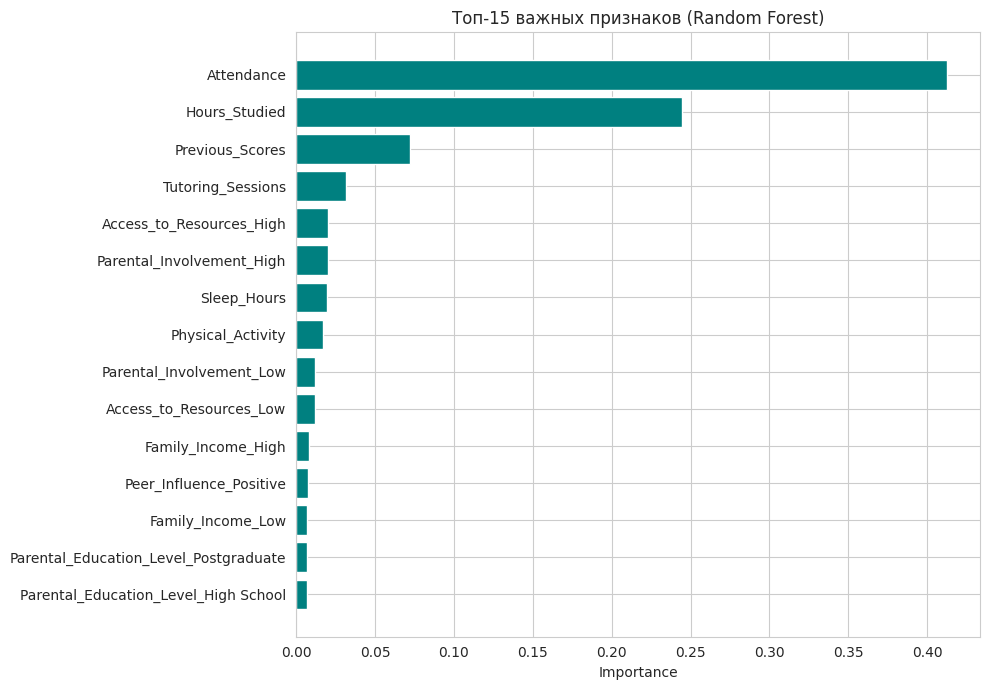

In [11]:

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_rf = best_model.named_steps["model"]

feat_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_rf.feature_importances_

imp_df = (
    pd.DataFrame({"feature": feat_names, "importance": importances})
      .sort_values("importance", ascending=False)
      .reset_index(drop=True)
)

imp_df["feature"] = (
    imp_df["feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

print("Топ-15 важных признаков:")
display(imp_df.head(15))

top_n = 15
top = imp_df.head(top_n).iloc[::-1]
plt.figure(figsize=(10, 7))
plt.barh(top["feature"], top["importance"], color="teal")
plt.xlabel("Importance")
plt.title(f"Топ-{top_n} важных признаков (Random Forest)")
plt.tight_layout()
plt.show()

## 12. Итоговый отчёт

Печатаем финальную сводку: параметры baseline и tuned-модели, метрики на тесте, топ-5 самых важных признаков. Удобно для вставки в вывод по лабораторной.

In [12]:

print("=" * 60)
print("ИТОГИ ЛАБОРАТОРНОЙ РАБОТЫ (чётный вариант — Random Forest)")
print("=" * 60)
print(f"Задача: регрессия (цель — Exam_Score)")
print(f"Размер данных: {df.shape[0]} строк, {df.shape[1]} столбцов")
print(f"Train / Test: {X_train.shape[0]} / {X_test.shape[0]}")
print()
print("Базовые параметры RF:", rf_baseline.named_steps['model'].get_params())
print("Лучшие параметры RF   :", grid_search.best_params_)
print()
print("Метрики на тесте:")
print(f"  Baseline — RMSE={metrics_baseline_test['RMSE']:.4f}, R²={metrics_baseline_test['R2']:.4f}")
print(f"  Tuned    — RMSE={metrics_best_test['RMSE']:.4f}, R²={metrics_best_test['R2']:.4f}")
print()
print("Топ-5 важных признаков:")
for i, row in imp_df.head(5).iterrows():
    print(f"  {i+1}. {row['feature']:<35s} {row['importance']:.4f}")
print("=" * 60)

ИТОГИ ЛАБОРАТОРНОЙ РАБОТЫ (чётный вариант — Random Forest)
Задача: регрессия (цель — Exam_Score)
Размер данных: 6607 строк, 20 столбцов
Train / Test: 5285 / 1322

Базовые параметры RF: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Лучшие параметры RF   : {'model__max_depth': None, 'model__max_features': 0.5, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Метрики на тесте:
  Baseline — RMSE=2.1657, R²=0.6682
  Tuned    — RMSE=2.0587, R²=0.7002

Топ-5 важных признаков:
  1. Attendance                          0.4129
  2. Hours_Studied                       0.2448
  3. Previous_Scores                   